In [1]:
%load_ext autoreload
%autoreload 2
import emcee
import corner
import pickle
import time
from astropy.table import QTable
from astropy import units as u
from astropy import constants as const
import pandas as pd

from multiprocessing import Pool

import numpy as np
from matplotlib import pyplot as plt

from asymmetric_uncertainty_mod import a_u
from nfw_profile_heating import NFWProfile
from statistics_functions import chi_squared
from plotting import savefig, paper_plot
from load_data_and_var import load_data_and_var, generate_nfws_from_combined_dataset_werr

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


In [2]:
reflex_clean, variances = load_data_and_var()
reflex_clean.head()

/Users/eleanorstuart/Desktop/krisp/thermo-idm/load_data_and_var.py:14: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  low_z_data = comb_data[comb_data['z_y'] < 0.2][comb_data['Sub-Cat']=='REFLEX'][['OName',


,OName,Name,L500,z_y,MSZ,e_MSZ,E_MSZ,L_err
2,RXCJ0003.8+0203,A2700,0.846881,0.0924,2.238774,0.301448,0.282160,0.136707
3,RXCJ0006.0-3443,A2721,1.809494,0.1147,4.001657,0.226974,0.248869,0.211627
6,RXCJ0011.3-2851,A2734,1.086002,0.0620,2.606369,0.188038,0.182667,0.086428
9,RXCJ0013.6-1930,A0013,1.236332,0.0940,2.756623,0.245311,0.233331,0.124160
10,RXCJ0014.3-6604,A2746,2.827248,0.1599,3.030337,0.347930,0.328876,0.313974


In [8]:
nfws_werr = generate_nfws_from_combined_dataset_werr(reflex_clean, variances)

In [9]:
nfws= [nfw for nfw in nfws_werr if nfw.energies.is_virialized_gaspari]
len(nfws)

111

In [10]:
max([n.z for n in nfws])

0.1926

In [11]:
test_nfw = nfws[0]

In [12]:
test_rs = np.logspace(-3, 0)*test_nfw.R500
test_rs

array([<asymmetric_uncertainty_mod.core.a_u object at 0x12f0850d0>,
      dtype=object)

Text(0, 0.5, 'v (km/s)')

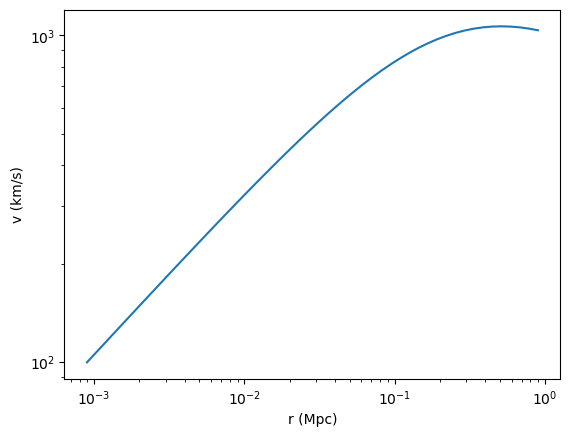

In [18]:
plt.loglog(test_rs, test_nfw.therm.velocity(test_rs))
plt.xlabel('r (Mpc)')
plt.ylabel('v (km/s)')

Text(0, 0.5, 'n_chi (1/Mpc3)')

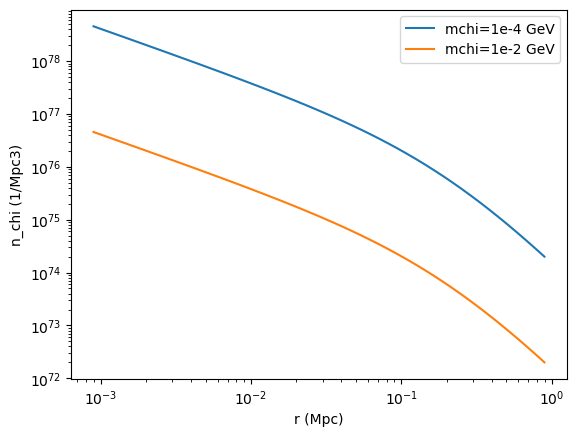

In [22]:
plt.loglog(test_rs, test_nfw.therm.dm_number_density(test_rs, 1e-4), label='mchi=1e-4 GeV')
plt.loglog(test_rs, test_nfw.therm.dm_number_density(test_rs, 1e-2), label='mchi=1e-2 GeV')
plt.legend()
plt.xlabel('r (Mpc)')
plt.ylabel('n_chi (1/Mpc3)')

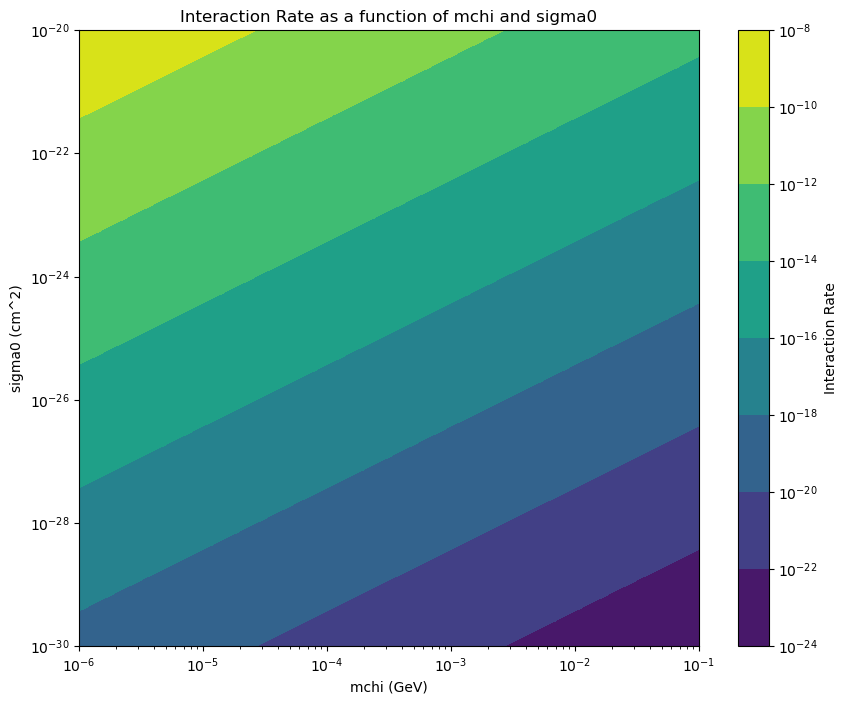

In [41]:
from matplotlib.colors import LogNorm

# Define the range of sigma0 and mchi values
sigma0_values = np.logspace(-30, -20, 50)  # Example range in cm^2
mchi_values = np.logspace(-6, -1, 50)       # Example range in GeV

# Create a meshgrid for sigma0 and mchi
sigma0_grid, mchi_grid = np.meshgrid(sigma0_values, mchi_values)

# Calculate the interaction rate for each combination of sigma0 and mchi
interaction_rate_grid = np.zeros_like(sigma0_grid)
for i in range(sigma0_grid.shape[0]):
    for j in range(sigma0_grid.shape[1]):
        sigma0 = sigma0_grid[i, j]
        mchi = mchi_grid[i, j]
        interaction_rate_grid[i, j] = test_nfw.therm.calculate_interaction_rate(sigma0, mchi)

# Plot the results
plt.figure(figsize=(10, 8))
cp = plt.contourf(mchi_grid, sigma0_grid, interaction_rate_grid, cmap='viridis', norm=LogNorm())
plt.colorbar(cp, label='Interaction Rate')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('mchi (GeV)')
plt.ylabel('sigma0 (cm^2)')
plt.title('Interaction Rate as a function of mchi and sigma0')
plt.show()

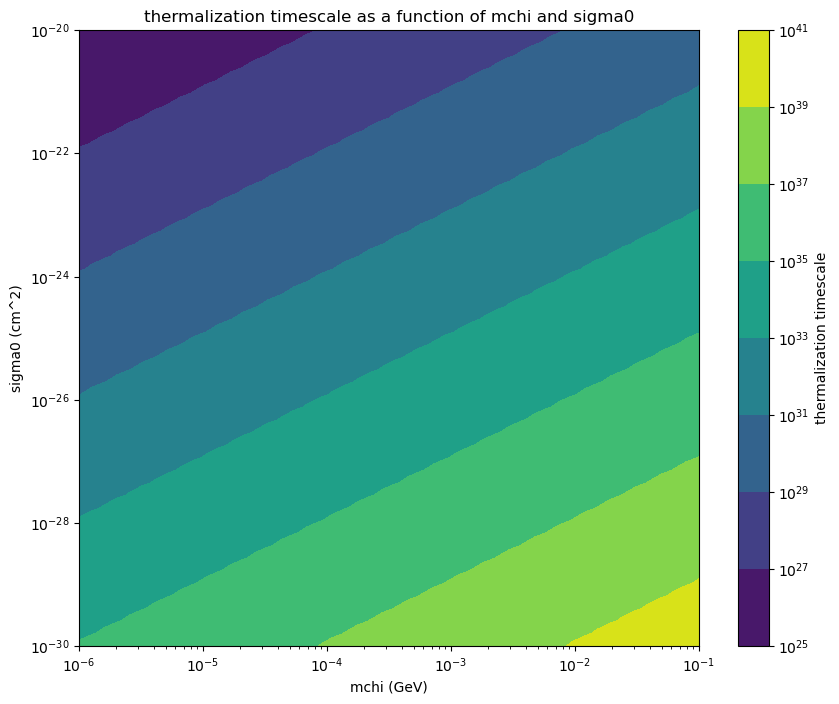

In [42]:
# Define the range of sigma0 and mchi values
sigma0_values = np.logspace(-30, -20, 50)  # Example range in cm^2
mchi_values = np.logspace(-6, -1, 50)       # Example range in GeV

# Create a meshgrid for sigma0 and mchi
sigma0_grid, mchi_grid = np.meshgrid(sigma0_values, mchi_values)

# Calculate the interaction rate for each combination of sigma0 and mchi
thermalization_grid = np.zeros_like(sigma0_grid)
for i in range(sigma0_grid.shape[0]):
    for j in range(sigma0_grid.shape[1]):
        sigma0 = sigma0_grid[i, j]
        mchi = mchi_grid[i, j]
        thermalization_grid[i, j] = test_nfw.therm.thermalization_timescale(sigma0, mchi)

# Plot the results
plt.figure(figsize=(10, 8))
cp = plt.contourf(mchi_grid, sigma0_grid, thermalization_grid, cmap='viridis', norm=LogNorm())
plt.colorbar(cp, label='thermalization timescale')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('mchi (GeV)')
plt.ylabel('sigma0 (cm^2)')
plt.title('thermalization timescale as a function of mchi and sigma0')
plt.show()

In [23]:
u.Mpc.to(u.cm)

3.085677581491367e+24

In [33]:
u.s.to(u.Gyr)

3.168808781402895e-17

In [46]:
(1/test_nfw.therm.calculate_interaction_rate(1e-4, 1e-27)).value

2.5345788523756063e+24 (+4.536782577130161e+23, -4.395743006635123e+23)
105326825.91872442 (+25631694.853638757, -25337655.870622292)


3.745891521704135e-29

In [40]:
u.s.to(u.Gyr)

3.168808781402895e-17

In [47]:
u.Gyr.to(u.s)

3.15576e+16

In [54]:
sigma0s_list = test_nfw.therm.sigma0_vs_mchi_from_interaction_rate_limit(mchi_values)

In [60]:
sigma0s_upper = [s0.value + s0.plus for s0 in sigma0s_list]

In [61]:
sigma0s_lower = [s0.value - s0.minus for s0 in sigma0s_list]

Text(0, 0.5, 'sigma0 (cm2)')

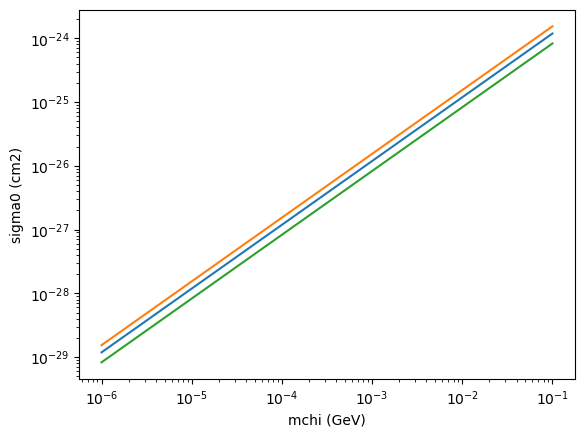

In [62]:
plt.loglog(mchi_values, sigma0s_list)
plt.loglog(mchi_values, sigma0s_upper)
plt.loglog(mchi_values, sigma0s_lower)
plt.xlabel('mchi (GeV)')
plt.ylabel('sigma0 (cm2)')
# above line does not satisfy interaction rate requirement

In [81]:
# Initialize a dictionary to store results for each mchi value
results = {mchi: [] for mchi in mchi_values}

# Iterate over each mchi value
for mchi in mchi_values:
    # For each mchi, iterate over each cluster and call the function
    for n in nfws:
        result = n.therm.sigma0_vs_mchi_from_interaction_rate_limit(mchi)
        results[mchi].append(result)

In [82]:
results

{1e-06: [<asymmetric_uncertainty_mod.core.a_u at 0x1321bac10>,
 1.2648552168552959e-06: [<asymmetric_uncertainty_mod.core.a_u at 0x1328eaa50>,
 1.5998587196060574e-06: [<asymmetric_uncertainty_mod.core.a_u at 0x13272d550>,
 2.0235896477251557e-06: [<asymmetric_uncertainty_mod.core.a_u at 0x1328e26d0>,
 2.5595479226995334e-06: [<asymmetric_uncertainty_mod.core.a_u at 0x1328f5090>,
 3.2374575428176467e-06: [<asymmetric_uncertainty_mod.core.a_u at 0x13292a4d0>,
 4.094915062380427e-06: [<asymmetric_uncertainty_mod.core.a_u at 0x132936450>,
 5.179474679231212e-06: [<asymmetric_uncertainty_mod.core.a_u at 0x1329467d0>,
 6.5512855685955095e-06: [<asymmetric_uncertainty_mod.core.a_u at 0x1329392d0>,
 8.286427728546843e-06: [<asymmetric_uncertainty_mod.core.a_u at 0x132943090>,
 1.0481131341546853e-05: [<asymmetric_uncertainty_mod.core.a_u at 0x13296dd10>,
 1.3257113655901109e-05: [<asymmetric_uncertainty_mod.core.a_u at 0x132975e50>,
 1.67683293681101e-05: [<asymmetric_uncertainty_mod.core.a_u

In [83]:
# Assuming results is a dictionary where each key is an mchi value and each value is a list of a_u objects
#results = {
    # Example structure
    # mchi_value1: [a_u_obj1, a_u_obj2, ...],
    # mchi_value2: [a_u_obj1, a_u_obj2, ...],
    # ...
#}

# Initialize dictionaries to store values and uncertainties
values_dict = {}
uncertainties_dict = {}

# Iterate over each mchi value in results
for mchi, a_u_list in results.items():
    # Initialize lists to store values and uncertainties for the current mchi
    values_list = []
    uncertainties_list = []
    
    # Iterate over each a_u object in the list
    for obj in a_u_list:
        # Extract the value and the approximate symmetric uncertainty
        value = obj.value
        uncertainty = (obj.plus + obj.minus) / 2
        
        # Append to the lists
        values_list.append(value)
        uncertainties_list.append(uncertainty)
    
    # Store the lists in the dictionaries
    values_dict[mchi] = values_list
    uncertainties_dict[mchi] = uncertainties_list

# Now values_dict contains the values and uncertainties_dict contains the uncertainties

In [84]:
values_dict

{1e-06: [1.1870013948158717e-29,
  1.1678662250084141e-29,
  1.106574540373045e-29,
  9.939773010106336e-30,
  1.434469051919916e-29,
  9.6120752597958e-30,
  1.0746682598172386e-29,
  1.18684568302705e-29,
  9.931853370674975e-30,
  1.119185744161156e-29,
  1.3208185313297526e-29,
  1.5948172275812898e-29,
  1.4191527834527325e-29,
  1.3663082597666564e-29,
  9.093071070939412e-30,
  1.2471473124551826e-29,
  1.1500091808027252e-29,
  1.282542127455888e-29,
  1.3190933911101733e-29,
  1.1079484137553937e-29,
  1.3151947046167258e-29,
  8.539298243761138e-30,
  1.0938567929200082e-29,
  1.397562513611082e-29,
  1.1909728197177382e-29,
  1.3113458653489774e-29,
  1.4128284720640242e-29,
  1.1895287500577037e-29,
  1.1943221254494953e-29,
  1.1753761713224555e-29,
  9.495607343528539e-30,
  1.3422786041938705e-29,
  1.207082933284367e-29,
  1.2671532537570836e-29,
  9.63396516978281e-30,
  9.32113591296126e-30,
  1.1404384296063286e-29,
  1.5824962659519724e-29,
  1.1368214316681107e-29,

In [85]:
uncertainties_dict

{1e-06: [3.5530193795579884e-30,
  1.906498158911807e-30,
  2.2072683183381964e-30,
  2.5539395010752206e-30,
  4.095211679688984e-30,
  2.094943039258521e-30,
  2.9009475252002477e-30,
  3.0795043732057757e-30,
  1.5141646080186483e-30,
  1.4621827026162882e-30,
  3.007358452663542e-30,
  3.6048017549584025e-30,
  5.177502156268456e-30,
  4.324167628158169e-30,
  1.719408840599652e-30,
  4.508677012732128e-30,
  3.34255634475344e-30,
  4.115797635212095e-30,
  4.660036545662071e-30,
  1.605948372456753e-30,
  3.295785997220653e-30,
  2.1352621824633867e-30,
  2.6344645028985055e-30,
  5.737183995409155e-30,
  1.868206925270657e-30,
  2.894904611726546e-30,
  3.530112804304142e-30,
  1.5105177618039851e-30,
  2.7455658169617455e-30,
  2.761434436519567e-30,
  1.577910799262074e-30,
  2.9912049141441907e-30,
  3.1294305636522764e-30,
  3.742397619044254e-30,
  2.287135174725368e-30,
  2.6897399345686905e-30,
  3.0924455274960186e-30,
  5.3209936441335615e-30,
  3.10555144763086e-30,
  3

In [86]:
results

{1e-06: [<asymmetric_uncertainty_mod.core.a_u at 0x1321bac10>,
 1.2648552168552959e-06: [<asymmetric_uncertainty_mod.core.a_u at 0x1328eaa50>,
 1.5998587196060574e-06: [<asymmetric_uncertainty_mod.core.a_u at 0x13272d550>,
 2.0235896477251557e-06: [<asymmetric_uncertainty_mod.core.a_u at 0x1328e26d0>,
 2.5595479226995334e-06: [<asymmetric_uncertainty_mod.core.a_u at 0x1328f5090>,
 3.2374575428176467e-06: [<asymmetric_uncertainty_mod.core.a_u at 0x13292a4d0>,
 4.094915062380427e-06: [<asymmetric_uncertainty_mod.core.a_u at 0x132936450>,
 5.179474679231212e-06: [<asymmetric_uncertainty_mod.core.a_u at 0x1329467d0>,
 6.5512855685955095e-06: [<asymmetric_uncertainty_mod.core.a_u at 0x1329392d0>,
 8.286427728546843e-06: [<asymmetric_uncertainty_mod.core.a_u at 0x132943090>,
 1.0481131341546853e-05: [<asymmetric_uncertainty_mod.core.a_u at 0x13296dd10>,
 1.3257113655901109e-05: [<asymmetric_uncertainty_mod.core.a_u at 0x132975e50>,
 1.67683293681101e-05: [<asymmetric_uncertainty_mod.core.a_u

In [80]:
results.items()

dict_items([(1e-06, [[<asymmetric_uncertainty_mod.core.a_u object at 0x131e95650>], [<asymmetric_uncertainty_mod.core.a_u object at 0x131a83510>], [<asymmetric_uncertainty_mod.core.a_u object at 0x1321e4110>], [<asymmetric_uncertainty_mod.core.a_u object at 0x131e97a10>], [<asymmetric_uncertainty_mod.core.a_u object at 0x13242d050>], [<asymmetric_uncertainty_mod.core.a_u object at 0x131e3f1d0>], [<asymmetric_uncertainty_mod.core.a_u object at 0x131b84e90>], [<asymmetric_uncertainty_mod.core.a_u object at 0x131c81850>], [<asymmetric_uncertainty_mod.core.a_u object at 0x1322a6850>], [<asymmetric_uncertainty_mod.core.a_u object at 0x13254fb90>], [<asymmetric_uncertainty_mod.core.a_u object at 0x131b236d0>], [<asymmetric_uncertainty_mod.core.a_u object at 0x1322c8290>], [<asymmetric_uncertainty_mod.core.a_u object at 0x1322a6f90>], [<asymmetric_uncertainty_mod.core.a_u object at 0x1319d6890>], [<asymmetric_uncertainty_mod.core.a_u object at 0x1322df090>], [<asymmetric_uncertainty_mod.core.

In [89]:
sigma0_means_list = []

# Iterate over each entry in values_dict
for mchi, values in values_dict.items():
    # Calculate the mean of the list of values
    mean_value = np.mean(values)
    
    # Append the calculated mean to means_list
    sigma0_means_list.append(mean_value)

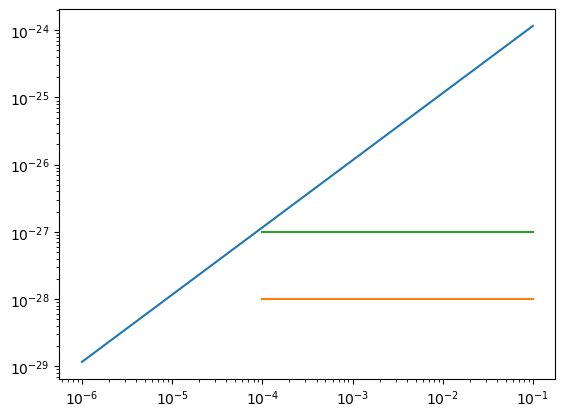

In [94]:
plt.loglog(mchi_values, sigma0_means_list)
plt.plot([1e-4, 1e-1], [1e-28, 1e-28])
plt.plot([1e-4, 1e-1], [1e-27, 1e-27])

In [99]:
# Iterate over each entry in values_dict and uncertainties_dict
s0_wmeans_list = []
for mchi in values_dict:
    values = values_dict[mchi]
    uncertainties = uncertainties_dict[mchi]
    
    # Calculate the variances (square of the uncertainties)
    variances = [uncertainty ** 2 for uncertainty in uncertainties]
    
    # Calculate the weighted mean
    weighted_mean = np.sum([value / variance for value, variance in zip(values, variances)]) / np.sum([1 / variance for variance in variances])
    
    # Append the calculated weighted mean to weighted_means_list
    s0_wmeans_list.append(weighted_mean)

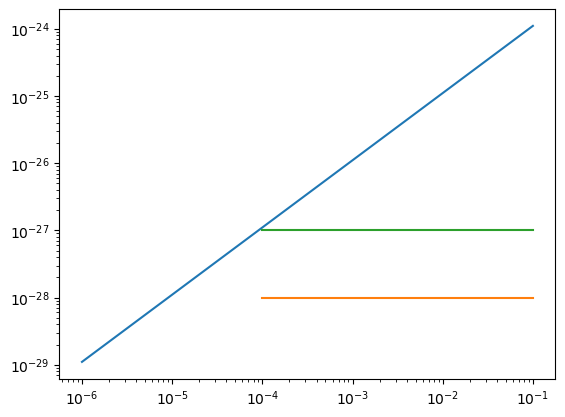

In [100]:
plt.loglog(mchi_values, s0_wmeans_list)
#plt.plot([1e-4, 1e-1], [1e-28, 1e-28])
#plt.plot([1e-4, 1e-1], [1e-27, 1e-27])

In [101]:
# Initialize a list to store the weighted variances
weighted_variances_list = []

# Iterate over each entry in values_dict and uncertainties_dict
for mchi in values_dict:
    values = values_dict[mchi]
    uncertainties = uncertainties_dict[mchi]
    
    # Calculate the variances (square of the uncertainties)
    variances = [uncertainty ** 2 for uncertainty in uncertainties]
    
    # Calculate the weighted mean
    weighted_mean = np.sum([value / variance for value, variance in zip(values, variances)]) / np.sum([1 / variance for variance in variances])
    
    # Calculate the weighted variance
    weighted_variance = np.sum([(value - weighted_mean) ** 2 / variance for value, variance in zip(values, variances)]) / np.sum([1 / variance for variance in variances])
    
    # Append the calculated weighted variance to weighted_variances_list
    weighted_variances_list.append(weighted_variance)

# Now weighted_variances_list contains the weighted variances for each entry in values_dict

In [103]:
weighted_variances_list

[2.1433439171955473e-60,
 3.4290474550399017e-60,
 5.485991470888541e-60,
 8.776811290385493e-60,
 1.404165807326013e-59,
 2.2464669106232095e-59,
 3.5940296752670242e-59,
 5.749939714498873e-59,
 9.199091189450185e-59,
 1.4717246251893148e-58,
 2.3545514744680805e-58,
 3.7669497071890735e-58,
 6.0265873353639234e-58,
 9.641688297949415e-58,
 1.5425339095198045e-57,
 2.4678363254332806e-57,
 3.9481894638050043e-57,
 6.316545340325201e-57,
 1.0105580140506289e-56,
 1.6167500504466801e-56,
 2.5865716656306563e-56,
 4.13814923314517e-56,
 6.620454133678436e-56,
 1.0591791273517405e-55,
 1.6945369625184176e-55,
 2.7110197351798534e-55,
 4.3372485623515906e-55,
 6.938984931577049e-55,
 1.1101395547998576e-54,
 1.776066446726139e-54,
 2.841455391394566e-54,
 4.54592718429424e-54,
 7.272841244487351e-54,
 1.1635518481303663e-53,
 1.8615185699451082e-53,
 2.9781667158352875e-53,
 4.764645988769618e-53,
 7.622760430969096e-53,
 1.2195339742953958e-52,
 1.9510820626323196e-52,
 3.121455650569288

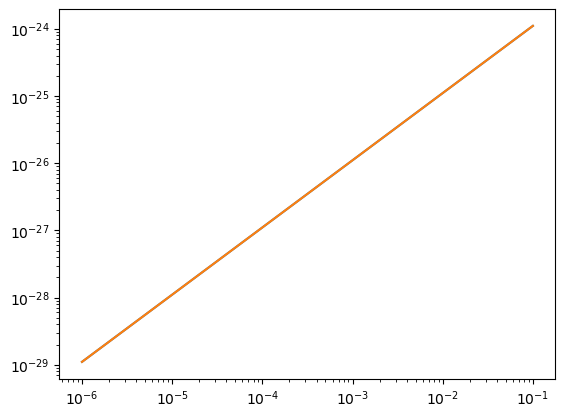

In [106]:
plt.loglog(mchi_values, s0_wmeans_list)
plt.loglog(mchi_values, np.add(s0_wmeans_list,weighted_variances_list))